In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

IVP_KWARGS = dict(max_step=0.02, rtol=1e-8, atol=1e-8)


def integrate(system, ic, t_end):
    return solve_ivp(system, [0, t_end], ic, **IVP_KWARGS)


def draw_stable_manifold(system, saddle, jacobian, eps=1e-4, T=20, color="blue", label=None):
    eigvals, eigvecs = np.linalg.eig(jacobian)
    stable_idx = np.argmin(np.real(eigvals))
    v = np.real(eigvecs[:, stable_idx])
    v /= np.linalg.norm(v)

    for i, sign in enumerate((-1, 1)):
        ic = np.array(saddle) + sign * eps * v
        sol = integrate(system, ic, -T)
        plot_kwargs = dict(color=color, lw=3)
        if label is not None and i == 0:
            plot_kwargs["label"] = label
        plt.plot(sol.y[0], sol.y[1], **plot_kwargs)


def phase_portrait(
    system,
    trajectories=None,
    fixed_points=None,
    nullclines=None,
    stable_manifolds=None,
    xlim=(-2, 2),
    ylim=(-2, 2),
    figsize=(8, 8),
    title=None,
):
    plt.figure(figsize=figsize)

    for ic in trajectories or []:
        sol = integrate(system, ic, 10)
        plt.plot(sol.y[0], sol.y[1], "k-", lw=2)

    for nc in nullclines or []:
        x = np.linspace(*nc["domain"], 1000)
        plt.plot(
            x,
            nc["function"](x),
            color=nc.get("color", "black"),
            lw=2,
            label=nc.get("label"),
        )

    for sm in stable_manifolds or []:
        draw_stable_manifold(
            system,
            sm["point"],
            sm["jacobian"],
            color=sm.get("color", "blue"),
            label=sm.get("label", "stable manifold"),
        )

    for p in fixed_points or []:
        plt.plot(*p, "ko")
        plt.annotate(str(p), p)

    plt.axhline(0, color="black")
    plt.axvline(0, color="black")
    plt.xlim(*xlim)
    plt.ylim(*ylim)
    plt.grid(True)

    if nullclines or stable_manifolds:
        plt.legend()
    if title:
        plt.title(title)

    plt.xlabel("x")
    plt.ylabel("y")
    plt.show()

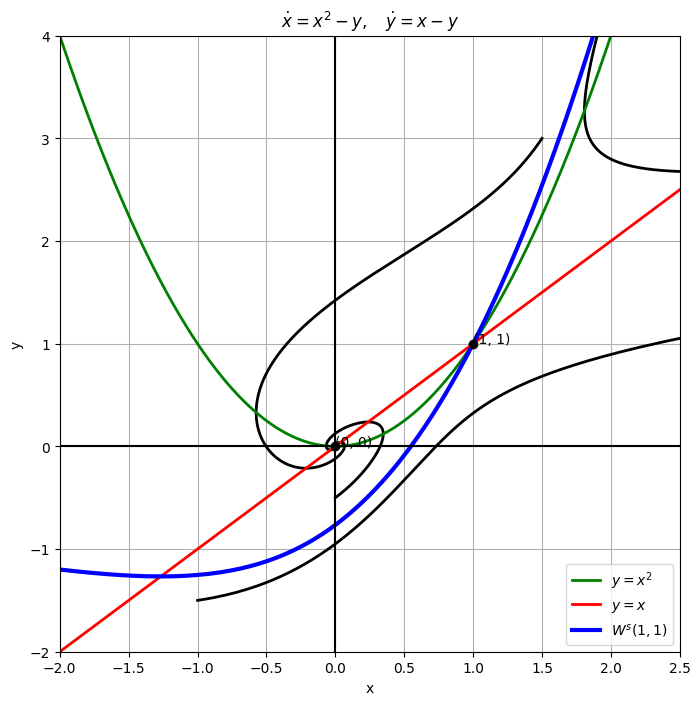

In [17]:
# Problem 1.2


def system(t, z):
    x, y = z
    return [x**2 - y, x - y]


J_11 = np.array([[2, -1], [1, -1]])

phase_portrait(
    system,
    trajectories=[
        # (0, 2), # sink to (0,0)
        (0, -0.5), # sink to (0,0)
        (1.5, 3), # sink to (0,0)
        (-1, -1.5), # escapes right
        (1.9, 4), # escapes right
        ],
    fixed_points=[(0, 0), (1, 1)],
    nullclines=[
        {
            "function": lambda x: x**2,
            "domain": (-3, 3),
            "color": "green",
            "label": r"$y=x^2$",
        },
        {"function": lambda x: x, "domain": (-3, 3), "color": "red", "label": r"$y=x$"},
    ],
    stable_manifolds=[{"point": (1, 1), "jacobian": J_11, "label": r"$W^s(1,1)$"}],
    xlim=(-2, 2.5),
    ylim=(-2, 4),
    title=r"$\dot x=x^2-y,\quad \dot y=x-y$",
)